# Week 4: explicit diffusion (FTCS), its stability limit, and the carburizing of steel

Tasks 0–4 of the week 4 assignment; [`../README.md`](../README.md) summarizes the tasks and results. The FTCS loop is written from scratch with NumPy slices; no PDE solver is called. `scipy.special.erfc` gives the exact solution, `quad` and `brentq` are used only as independent checks.

| File | Contents |
|---|---|
| `diffusion.py` | Task 0 and the exact solutions: erf with the Simpson rule of week 1, the erfc solution and its derivatives (Hermite polynomials), the residual of the diffusion equation, absorbed amount, iso-concentration depth, the two-stage superposition |
| `ftcs.py` | Tasks 1–3: `ftcs(M, L, r, T, cs, c0, right, corner)` with Dirichlet or zero-flux right end, the integer-step assertion, the hand calculation of lecture notes §5.4, the periodic step, amplification factors, the exact stability limit with fixed ends, and the r → 0 limit (method of lines) |
| `carburizing.py` | Task 4: Wells–Mehl diffusivity, case-depth times, single-stage and boost–diffuse FTCS runs in real units |
| `test_*.py` | Automated tests (48) |
| `figures/` | `fig1_ftcs.png`, `fig2_stability.png`, `fig3_convergence.png`, `fig4_carburizing.png` |

**Run:** `conda activate cms`, then in `week04/work` run `pytest -q` and `jupyter lab lab04.ipynb` → Run All (well under a minute).

**Defaults** (from the assignment unless a task says otherwise): D = 1, Cₛ = 1, C₀ = 0, T = 1, L = 10, Dirichlet right end c = C₀, corner c₀⁰ = Cₛ. The number of steps N = T/Δt is computed with `round` and asserted to satisfy |NΔt − T| < 10⁻⁹T. "Maximum error" is the largest |cᵢ − c_exact(xᵢ, T)| over all grid points at t = T.

**Verification standard:** each number is checked against theory, a closed form or an exact formula, not only against the course's reference solution (called "05" below; not included in this repository). The independent checks used this week:

- Task 0: erf from the week 1 Simpson rule; erfcinv against a `brentq` root of erfc; the residual of the diffusion equation against its predicted truncation error (h²/12)c_xxxx and (h²/6)c_ttt, from the exact derivatives.
- Task 1: the absorbed amount 2√(t/π); the error split into "half a step early" plus the error of the mean-corner run; scale invariance checked for identity, not closeness.
- Task 2: the measured amplification of a cosine against 1 − 4r sin²(θ/2); the stability limit with fixed ends against the eigenvalues of the tridiagonal matrix; the r = ½ run against the coarse r = ¼ run.
- Task 3: the r → 0 limit computed directly from the semi-discrete system (eigen-decomposition), which predicts the whole error-versus-r curve of the mean corner.
- Task 4: the boost–diffuse run against the exact superposition solution and its `brentq` time.

The 05 values are listed next to the summary table at the end for reference; the places where the two differ are collected in the last section.

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.linalg import eigvalsh_tridiagonal
from scipy.optimize import brentq
from scipy.special import erf, erfc, erfcinv

from diffusion import (erf_simpson, erfc_solution, ct_exact, erfc_x_derivative, pde_residual, absorbed,
                       depth_exact, depth_interp, two_stage_solution)
from ftcs import (ftcs, time_steps, hand_steps, ftcs_periodic_step, amplification, exact_decay,
                  fixed_ends_growth, r_limit, method_of_lines)
from carburizing import (C0, CASE, HOUR, wells_mehl, case_time, grid_steps, single_stage, two_stage,
                         two_stage_exact_time)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': 0.3})


def max_err(M, L, r, T, t_exact=None, **kw):
    # maximum error of the last step of ftcs(...) against erfc at t_exact (default T)
    x, c, _ = ftcs(M, L, r, T, **kw)
    return np.abs(c - erfc_solution(x, T if t_exact is None else t_exact)).max()


def history(M, L, r, T, **kw):
    # profile at the end and the maximum error after every step, against erfc at t_n
    xg = np.linspace(0, L, M + 1)
    errs = []
    x, c, _ = ftcs(M, L, r, T, callback=lambda n, t, c: errs.append(np.abs(c - erfc_solution(xg, t)).max()), **kw)
    return x, c, np.array(errs)


# Every number the report needs is collected here and tabulated at the end:
# (task, quantity, this run, independent check value, what the check is, value printed in 05)
summary = []
def record(task, name, ours, check, how, ref05):
    summary.append((task, name, float(ours), None if check is None else float(check), how, ref05))

## Automated tests (48)

The functions are in three `.py` files; the cell below runs pytest and lists every result. Each test checks a property predicted by the derivation, not just that "a number comes out":

- `test_diffusion.py`
  - erf from the Simpson rule agrees with `scipy.special.erf` to 10⁻¹²; the values of lecture notes §0.3.
  - The erfc solution satisfies c_t = c_xx: by central differences (the assignment's tolerances), by the complex step, and the residual equals the predicted truncation error.
  - The Hermite-polynomial derivatives agree with the complex step and with each other.
  - The absorbed amount equals the integral of the profile; the worked examples and hand-calculation exercise 5.3; the two-stage superposition reduces to the single stage at the switch and has surface value C_d afterwards.
- `test_ftcs.py`
  - `round`, not `int`, for the number of steps, and the assertion for a non-integer T/Δt.
  - The hand table of lecture notes §5.4 for r = 0.25, 0.5, 1 digit for digit; hand-calculation exercise 5.4 (two steps, zero-flux end).
  - The whole-row update equals a point-by-point loop with a copy of the old row; overwriting in place gives a different answer without an error.
  - The discrete maximum principle for r ≤ ½; r = 0.6 produces −0.2 from 0, 1, 0; a straight line is a steady state.
  - A periodic cosine is multiplied by exactly g = 1 − 4r sin²(θ/2); the tables of lecture notes §5.7; the exact stability limit with fixed ends.
  - Task 1 default run; scale invariance is exact; r = ½ even nodes equal the r = ¼ coarse grid; M = 10 is stable at r = 0.51 and not at 0.515.
  - Orders 2 and 4; corner Cₛ is the exact solution half a step later; the method-of-lines limit.
- `test_carburizing.py`
  - Wells–Mehl values and the case-depth table of lecture notes §5.9, hand-calculation exercise 5.9.
  - The single-stage FTCS run against erfc and the two-stage run against superposition.

In [2]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-v', '--no-header', '--color=no', '-p', 'no:cacheprovider'],
                   capture_output=True, text=True)
print(r.stdout[-9000:] or r.stderr)

============================= test session starts =============================
collecting ... collected 48 items

test_carburizing.py::test_wells_mehl_lecture_values PASSED               [  2%]
test_carburizing.py::test_case_time_table_lecture_5_9 PASSED             [  4%]
test_carburizing.py::test_grid_steps_keeps_r_just_below_r0 PASSED        [  6%]
test_carburizing.py::test_single_stage_matches_erfc PASSED               [  8%]
test_carburizing.py::test_two_stage_against_superposition PASSED         [ 10%]
test_diffusion.py::test_erf_simpson_matches_scipy[0.25] PASSED           [ 12%]
test_diffusion.py::test_erf_simpson_matches_scipy[0.5] PASSED            [ 14%]
test_diffusion.py::test_erf_simpson_matches_scipy[1.0] PASSED            [ 16%]
test_diffusion.py::test_erf_simpson_matches_scipy[1.5] PASSED            [ 18%]
test_diffusion.py::test_erf_simpson_matches_scipy[2.0] PASSED            [ 20%]
test_diffusion.py::test_erf_simpson_matches_scipy[3.0] PASSED            [ 22%]
test_

## Task 0: the error function and a hand-calculation warm-up (lecture notes §0.3, §5.3, §5.4)

### Steps 1–2: erf, erfc and erfcinv

erf(z) = (2/√π)∫₀^z e^{−u²} du is also computed with the Simpson rule of week 1 (1000 sub-intervals, imported from `week01/work/quadrature.py`). Each erfcinv value is checked against a root of erfc(z) = p found by `brentq`.

In [3]:
Z = (0.25, 0.5, 1.0, 1.5, 2.0, 3.0)
print('    z    erf(z)            erfc(z)              Simpson N = 1000     Simpson - erf')
d_simp = []
for z in Z:
    s = erf_simpson(z)
    d_simp.append(abs(s - erf(z)))
    print(f'{z:5.2f}   {erf(z):.12f}   {erfc(z):.10e}   {s:.15f}   {s - erf(z):+.1e}')
print(f'max |Simpson - erf| = {max(d_simp):.1e}')
record('0', 'erf(1)', erf(1), erf_simpson(1.0), 'Simpson N=1000 (week 1)', '0.842701')
record('0', 'erfc(2)', erfc(2), 1 - erf_simpson(2.0), '1 - Simpson N=1000', '4.6777e-3')
record('0', 'max |Simpson - erf|, six z', max(d_simp), 0, 'exact', '7e-14')
print()
print('   p    erfcinv(p)       brentq root of erfc(z) = p   difference')
for p, ref in ((0.5, '0.476936'), (0.25, '0.813420'), (0.01, '1.821386')):
    root = brentq(lambda z: erfc(z) - p, 0, 5, xtol=1e-15, rtol=1e-15)
    print(f'{p:5}   {erfcinv(p):.12f}   {root:.12f}               {erfcinv(p) - root:+.1e}')
    record('0', f'erfcinv({p})', erfcinv(p), root, 'brentq on erfc', ref)

    z    erf(z)            erfc(z)              Simpson N = 1000     Simpson - erf
 0.25   0.276326390168   7.2367360983e-01   0.276326390168237   +5.6e-17
 0.50   0.520499877813   4.7950012219e-01   0.520499877813048   +1.4e-15
 1.00   0.842700792950   1.5729920705e-01   0.842700792949724   +9.2e-15
 1.50   0.966105146475   3.3894853525e-02   0.966105146475281   -3.0e-14
 2.00   0.995322265019   4.6777349810e-03   0.995322265018879   -7.4e-14
 3.00   0.999977909503   2.2090496999e-05   0.999977909502990   -1.1e-14
max |Simpson - erf| = 7.4e-14

   p    erfcinv(p)       brentq root of erfc(z) = p   difference
  0.5   0.476936276204   0.476936276204               -1.1e-16
 0.25   0.813419847598   0.813419847598               -2.2e-16
 0.01   1.821386367718   1.821386367718               +2.2e-16


### Step 3: the erfc solution satisfies the diffusion equation

c = erfc(x/(2√t)) with D = 1; c_t by a central difference with step 10⁻⁴, c_xx by the second difference with step 10⁻³, and the analytic c_t = x e^{−x²/(4t)}/(2√π t^{3/2}). The residual of the two differences is not zero: by week 2 it should be (h_t²/6)c_ttt − (h_x²/12)c_xxxx, where c_ttt = c_xxxxxx because c_t = c_xx. Both derivatives are exact here (Hermite polynomials, `erfc_x_derivative`), so the residual can be predicted.

In [4]:
print('  (x, t)       c_t (central)      c_xx (central)     c_t - c_xx   |res|/c_t   c_t analytic       rel. diff   c_xxxx    predicted residual')
res0 = {}
for (x0, t0), ref, ref_ct in (((0.5, 0.2), '6.8e-7', '1.1537271'), ((1.0, 1.0), '2.4e-8', '0.21969565'),
                              ((2.0, 3.0), '2.6e-9', '0.077799777')):
    ct, cxx, rs = pde_residual(x0, t0)
    ca = ct_exact(x0, t0)
    c4 = erfc_x_derivative(x0, t0, 4)
    pred = 1e-8 / 6 * erfc_x_derivative(x0, t0, 6) - 1e-6 / 12 * c4
    res0[(x0, t0)] = (rs, c4, pred)
    print(f'({x0}, {t0})   {ct:.12f}   {cxx:.12f}   {rs:+.2e}    {abs(rs) / ct:.1e}    {ca:.12f}   {abs(ct / ca - 1):.1e}    {c4:+7.3f}   {pred:+.2e}')
    record('0', f'c_t (central) at ({x0:g}, {t0:g})', ct, ca, 'analytic c_t', ref_ct)
    record('0', f'c_t - c_xx at ({x0:g}, {t0:g})', rs, pred, 'h^2 truncation terms', ref)

  (x, t)       c_t (central)      c_xx (central)     c_t - c_xx   |res|/c_t   c_t analytic       rel. diff   c_xxxx    predicted residual
(0.5, 0.2)   1.153727101735   1.153726420955   +6.81e-07    5.9e-07    1.153726991883   9.5e-08     -6.850   +6.81e-07
(1.0, 1.0)   0.219695645672   0.219695621806   +2.39e-08    1.1e-07    0.219695644734   4.3e-09     -0.275   +2.38e-08
(2.0, 3.0)   0.077799777411   0.077799774845   +2.57e-09    3.3e-08    0.077799777379   4.2e-10     -0.030   +2.55e-09


### Step 4: three FTCS steps by hand (lecture notes §5.4)

Seven points, c₀ = 1 and c₆ = 0 held fixed, the rest start at 0. The exact values after three steps, t = 3rΔx²/D, are erfc(i/(2√(3r))).

In [5]:
hand = {}
for r_ in (0.25, 0.5, 1.0):
    hand[r_] = hand_steps(r_)
    for n, row in enumerate(hand[r_], 1):
        print(f'r = {r_:<4}  step {n}:  ' + '  '.join(f'{v:9.6f}' for v in row))
    ex = erfc(np.arange(1, 4) / (2 * np.sqrt(3 * r_)))
    print(f'          exact after 3 steps, c1..c3:   ' + '  '.join(f'{v:.4f}' for v in ex))
    print(f'          weights r, 1 - 2r, r = {r_}, {1 - 2 * r_}, {r_}')
record('0', 'hand r=0.25: c1 after 3 steps', hand[0.25][2][1], 0.453125, 'lecture notes §5.4', '0.453125')
record('0', 'hand r=0.25: c3 after 3 steps', hand[0.25][2][3], 0.015625, 'lecture notes §5.4', '0.015625')
record('0', 'hand r=1: c1 after 3 steps', hand[1.0][2][1], 2, 'lecture notes §5.4', '2')
record('0', 'hand r=1: c2 after 3 steps', hand[1.0][2][2], -1, 'lecture notes §5.4', '-1')

r = 0.25  step 1:   1.000000   0.250000   0.000000   0.000000   0.000000   0.000000   0.000000
r = 0.25  step 2:   1.000000   0.375000   0.062500   0.000000   0.000000   0.000000   0.000000
r = 0.25  step 3:   1.000000   0.453125   0.125000   0.015625   0.000000   0.000000   0.000000
          exact after 3 steps, c1..c3:   0.4142  0.1025  0.0143
          weights r, 1 - 2r, r = 0.25, 0.5, 0.25
r = 0.5   step 1:   1.000000   0.500000   0.000000   0.000000   0.000000   0.000000   0.000000
r = 0.5   step 2:   1.000000   0.500000   0.250000   0.000000   0.000000   0.000000   0.000000
r = 0.5   step 3:   1.000000   0.625000   0.250000   0.125000   0.000000   0.000000   0.000000
          exact after 3 steps, c1..c3:   0.5637  0.2482  0.0833
          weights r, 1 - 2r, r = 0.5, 0.0, 0.5
r = 1.0   step 1:   1.000000   1.000000   0.000000   0.000000   0.000000   0.000000   0.000000
r = 1.0   step 2:   1.000000   0.000000   1.000000   0.000000   0.000000   0.000000   0.000000
r = 1.0   step 3

### Step 5: the total absorbed amount

In [6]:
val, est = quad(lambda x: erfc(x / 2), 0, np.inf)
print(f'int_0^inf erfc(x/2) dx = {val:.15f}  (quad error estimate {est:.1e})')
print(f'2/sqrt(pi)             = {2 / np.sqrt(np.pi):.15f}   difference {val - 2 / np.sqrt(np.pi):+.1e}')
record('0', 'int_0^inf erfc(x/2) dx', val, 2 / np.sqrt(np.pi), '2/sqrt(pi)', '1.1283792')

int_0^inf erfc(x/2) dx = 1.128379167095513  (quad error estimate 1.4e-09)
2/sqrt(pi)             = 1.128379167095513   difference +2.2e-16


**Reading the results:**

- **erf and erfcinv.** erf(1) = 0.842701 and erfc(2) = 4.6777×10⁻³; the Simpson rule of week 1 agrees with `erf` to 7.4×10⁻¹⁴ for all six z. erfcinv(0.5, 0.25, 0.01) = 0.476936, 0.813420, 1.821386, and each agrees with the `brentq` root of erfc(z) = p to round-off.
- **Why the residual at (0.5, 0.2) is the largest.** The residual is not a property of erfc but the truncation error of the two differences: the prediction (h_t²/6)c_ttt − (h_x²/12)c_xxxx from the exact derivatives matches the measured residual at all three points (to 1.1×10⁻⁴, 1.8×10⁻³ and 5.2×10⁻³ relative). At t = 0.2 the profile is steep and narrow, so c_xxxx = −6.850 there, 25 times its size at (1, 1) (−0.275) and over 200 times that at (2, 3) (−0.030); the second-difference error ∝ h²c_xxxx follows. The residuals relative to c_t, 5.9×10⁻⁷, 1.1×10⁻⁷ and 3.3×10⁻⁸, are all within the assignment's 10⁻⁵, and the analytic c_t agrees with the central difference to 10⁻⁷ or better.
- **Hand calculation.** The rows are exactly those of lecture notes §5.4: for r = 0.25, (0.453125, 0.125, 0.015625) after three steps; for r = 1, (2, −1, 1). With r = 1 the weights are r, 1 − 2r, r = 1, −1, 1: the centre enters with a negative weight, so the "average" becomes an extrapolation. After step 2 the row is (1, 0, 1, 0, …), and step 3 gives c₁ = 1 − 0 + 1 = 2 and c₂ = 0 − 1 + 0 = −1, outside [C₀, Cₛ].
- **Absorbed amount.** ∫₀^∞ erfc(x/2) dx agrees with 2/√π to 2×10⁻¹⁶.

## Task 1: FTCS for diffusion into a semi-infinite solid (lecture notes §5.3, §5.4, §5.8)

`ftcs(M, L, r, T, cs, c0, right, corner)` returns x, c at t = T and the profiles at the requested times. Default run: D = 1, L = 10, M = 100 (Δx = 0.1), r = 0.4, so Δt = 0.004 and N = 250.

### Steps 2–3: the default run

In [7]:
M, L, r, T = 100, 10.0, 0.4, 1.0
dt, N = time_steps(r, L / M, T)
x, c, snaps = ftcs(M, L, r, T, snapshots=(0.1, 0.5, 1.0))
e1 = c - erfc_solution(x, T)
i1 = np.argmax(np.abs(e1))
print(f'dx = {L / M}, dt = {dt!r}, N = {N}   (int(T/dt) would give {int(T / dt)})')
print(f'max error at t = 1: {abs(e1[i1]):.6e} at x = {x[i1]:.1f}; FTCS {"above" if e1[i1] > 0 else "below"} the exact solution')
for xv in (0.5, 1.0, 2.0):
    i = round(xv / (L / M))
    print(f'x = {xv}:  FTCS {c[i]:.6f}   exact {erfc_solution(xv, T):.6f}   error {c[i] - erfc_solution(xv, T):+.3e}')
neg = x[e1 < 0]
print(f'min c = {c.min()}, max c = {c.max()}')
print(f'most negative error {e1.min():.2e} at x = {x[np.argmin(e1)]:.1f}; the error is negative for x >= {neg.min():.1f}')
record('1', 'x of the max error', x[i1], None, '', '1.1')
record('1', 'c(1, 1)', c[10], erfc_solution(1.0, T), 'erfc', '0.480003')
record('1', 'min c', c.min(), 0, 'max. principle: C0', '0')
record('1', 'max c', c.max(), 1, 'max. principle: Cs', '1')
record('1', 'most negative error (x = 3.7)', e1.min(), None, '', '-4.8e-5')

dx = 0.1, dt = 0.004000000000000001, N = 250   (int(T/dt) would give 249)
max error at t = 1: 5.112257e-04 at x = 1.1; FTCS above the exact solution
x = 0.5:  FTCS 0.724006   exact 0.723674   error +3.322e-04
x = 1.0:  FTCS 0.480003   exact 0.479500   error +5.032e-04
x = 2.0:  FTCS 0.157594   exact 0.157299   error +2.945e-04
min c = 0.0, max c = 1.0
most negative error -4.82e-05 at x = 3.7; the error is negative for x >= 3.0


### Steps 4–6: absorbed amount, iso-concentration depth, scale invariance

The absorbed amount ∫₀^L c dx (trapezoid rule) against 2√(t/π), and against 2√((t + Δt/2)/π), the exact amount half a step later. The last column is the half-step prediction of the maximum error, (Δt/2) max c_t = (Δt/2)·0.2420/t (lecture notes §5.8).

In [8]:
CT1 = ct_exact(np.sqrt(2.0), 1.0)          # max over x of c_t at t = 1, at x = sqrt(2): 0.2420
print(f'max c_t at t = 1: {CT1:.4f} (x = sqrt 2)')
print('   t     absorbed     2 sqrt(t/pi)  rel. diff   2 sqrt((t+dt/2)/pi)  difference    max error   (dt/2) 0.2420/t')
for t_, ref_m, ref_e in ((0.1, '0.360817', '5.06e-3'), (0.5, '0.799678', '1.02e-3'), (1.0, '1.129648', '5.11e-4')):
    m = np.trapezoid(snaps[t_], x)
    mh = absorbed(t_ + dt / 2)
    em = np.abs(snaps[t_] - erfc_solution(x, t_)).max()
    print(f'{t_:5.1f}   {m:.6f}     {absorbed(t_):.6f}      {m / absorbed(t_) - 1:+.4%}    {mh:.6f}             {m - mh:+.2e}     {em:.3e}    {dt / 2 * CT1 / t_:.3e}')
    if t_ == 1.0:
        record('1', 'absorbed amount, t = 1', m, absorbed(t_), '2 sqrt(t/pi)', ref_m)
        record('1', 'absorbed amount, t = 1, half step', m, mh, '2 sqrt((t + dt/2)/pi)', '1.4e-4 diff.')
    record('1', f'max error, t = {t_:g}', em, dt / 2 * CT1 / t_, 'half step (dt/2) c_t', ref_e)
print()
d_num, d_ex = depth_interp(x, c, 0.5), depth_exact(0.5, T)
print(f'depth of c = 0.5 at t = 1: {d_num:.4f} (linear interpolation), exact 2 erfcinv(0.5) sqrt(t) = {d_ex:.4f}, difference {d_num - d_ex:+.4f}')
record('1', 'depth of c = 0.5, t = 1', d_num, d_ex, '2 erfcinv(0.5) sqrt(t)', '0.9556')
print()
scale = {}
for dx_, T_, L_ in ((0.1, 1.0, 10.0), (0.2, 4.0, 20.0), (0.05, 0.25, 5.0)):
    scale[(dx_, T_, L_)] = max_err(round(L_ / dx_), L_, 0.4, T_)
    print(f'(dx, T, L) = ({dx_}, {T_}, {L_}):  M = {round(L_ / dx_)}, N = {time_steps(0.4, dx_, T_)[1]}, max error = {scale[(dx_, T_, L_)]:.10e}')
print('all three identical (==):', len(set(scale.values())) == 1)
record('1', 'scale (0.2, 4, 20): max error', scale[(0.2, 4.0, 20.0)], scale[(0.1, 1.0, 10.0)], 'run (0.1, 1, 10)', '5.112257e-4')
record('1', 'scale (0.05, 0.25, 5): max error', scale[(0.05, 0.25, 5.0)], scale[(0.1, 1.0, 10.0)], 'run (0.1, 1, 10)', '5.112257e-4')

max c_t at t = 1: 0.2420 (x = sqrt 2)
   t     absorbed     2 sqrt(t/pi)  rel. diff   2 sqrt((t+dt/2)/pi)  difference    max error   (dt/2) 0.2420/t
  0.1   0.360817     0.356825      +1.1189%    0.360375             +4.42e-04     5.056e-03    4.839e-03
  0.5   0.799678     0.797885      +0.2248%    0.799479             +1.99e-04     1.024e-03    9.679e-04
  1.0   1.129648     1.128379      +0.1124%    1.129507             +1.41e-04     5.112e-04    4.839e-04

depth of c = 0.5 at t = 1: 0.9556 (linear interpolation), exact 2 erfcinv(0.5) sqrt(t) = 0.9539, difference +0.0017

(dx, T, L) = (0.1, 1.0, 10.0):  M = 100, N = 250, max error = 5.1122574131e-04
(dx, T, L) = (0.2, 4.0, 20.0):  M = 100, N = 250, max error = 5.1122574131e-04
(dx, T, L) = (0.05, 0.25, 5.0):  M = 100, N = 250, max error = 5.1122574131e-04
all three identical (==): True


### Where the error comes from: half a step early

Lecture notes §5.8: with c₀⁰ = Cₛ the first step puts in about twice the right amount, and afterwards the numerical solution is close to the exact solution at t + Δt/2. If that is the whole story, the error should split into the half-step part (Δt/2)c_t, which is positive everywhere, plus the error of the same run with the mean corner (Cₛ + C₀)/2, which has no half-step shift.

In [9]:
_, c_mean, _ = ftcs(M, L, r, T, corner=0.5)
e_mean = c_mean - erfc_solution(x, T)
shift = dt / 2 * ct_exact(x, T)
gap = np.abs(e1 - shift - e_mean).max()
print(f'max |e_Cs - (dt/2) c_t - e_mean| = {gap:.1e}   (max |e_Cs| = {np.abs(e1).max():.2e}, ratio {gap / np.abs(e1).max():.1e})')
print(f'half-step part (dt/2) c_t: max {shift.max():.3e} at x = {x[np.argmax(shift)]:.1f}, positive for every x > 0')
print(f'mean-corner part: max {e_mean.max():.2e}, min {e_mean.min():.3e} at x = {x[np.argmin(e_mean)]:.1f}, negative for x >= {x[(e_mean < 0)].min():.1f}')
i_neg = np.argmin(e1)
print(f'at x = {x[i_neg]:.1f}: e_Cs = {e1[i_neg]:+.2e} = half step {shift[i_neg]:+.2e} + mean corner {e_mean[i_neg]:+.2e}')
print(f'c_xxxx of the exact solution at t = 1 changes sign at x = 2 sqrt(3/2) = {2 * np.sqrt(1.5):.3f}')
record('1', 'max |e_Cs - (dt/2)c_t - e_mean|', gap, 0, 'exact if half-step only', '')

max |e_Cs - (dt/2) c_t - e_mean| = 6.2e-07   (max |e_Cs| = 5.11e-04, ratio 1.2e-03)
half-step part (dt/2) c_t: max 4.839e-04 at x = 1.4, positive for every x > 0
mean-corner part: max 7.67e-05, min -1.902e-04 at x = 2.7, negative for x >= 1.5
at x = 3.7: e_Cs = -4.82e-05 = half step +6.81e-05 + mean corner -1.16e-04
c_xxxx of the exact solution at t = 1 changes sign at x = 2 sqrt(3/2) = 2.449


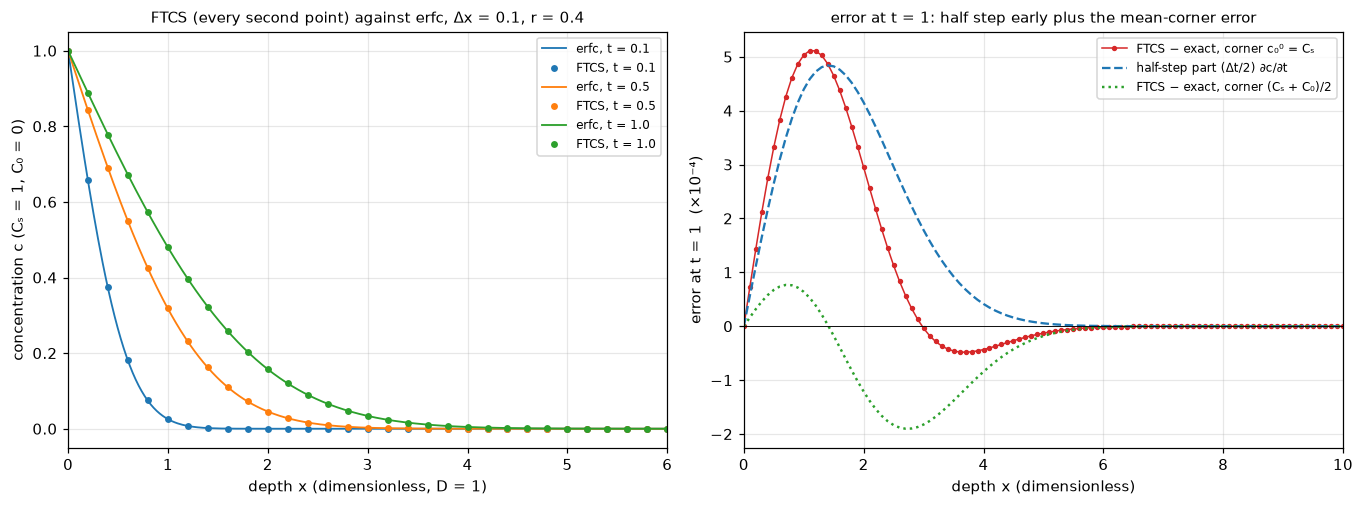

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.7))
xf = np.linspace(0, 6, 400)
for k, t_ in enumerate((0.1, 0.5, 1.0)):
    ax1.plot(xf, erfc_solution(xf, t_), color=f'C{k}', lw=1.2, label=f'erfc, t = {t_}')
    ax1.plot(x[:61:2], snaps[t_][:61:2], 'o', ms=3.5, color=f'C{k}', label=f'FTCS, t = {t_}')
ax1.set_xlim(0, 6)
ax1.set_xlabel('depth x (dimensionless, D = 1)')
ax1.set_ylabel('concentration c (Cₛ = 1, C₀ = 0)')
ax1.set_title('FTCS (every second point) against erfc, Δx = 0.1, r = 0.4', fontsize=10)
ax1.legend(fontsize=8)
ax2.plot(x, e1 * 1e4, 'o-', ms=2.5, lw=1, color='C3', label='FTCS − exact, corner c₀⁰ = Cₛ')
ax2.plot(x, shift * 1e4, '--', color='C0', label='half-step part (Δt/2) ∂c/∂t')
ax2.plot(x, e_mean * 1e4, ':', lw=1.6, color='C2', label='FTCS − exact, corner (Cₛ + C₀)/2')
ax2.axhline(0, color='k', lw=0.6)
ax2.set_xlim(0, 10)
ax2.set_xlabel('depth x (dimensionless)')
ax2.set_ylabel('error at t = 1  (×10⁻⁴)')
ax2.set_title('error at t = 1: half step early plus the mean-corner error', fontsize=10)
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'fig1_ftcs.png', bbox_inches='tight')
plt.show()

**Reading the results:**

- **The default run.** Δt = 0.004 is stored as 0.004000000000000001, so `int(T/Δt)` would give 249 steps; `round` gives 250. The maximum error at t = 1 is 5.112×10⁻⁴ at x = 1.1, with FTCS above the exact solution; at x = 1 FTCS gives 0.480003 against the exact 0.479500. The solution stays inside [C₀, Cₛ] = [0, 1], as the maximum principle of lecture notes §5.6 requires for r ≤ ½.
- **Half a step early is the whole story.** The error equals (Δt/2)c_t plus the error of the mean-corner run to 6.2×10⁻⁷, about 0.1% of the error itself. That is why the error is mainly positive: c increases with time at every depth, so a solution that is half a step ahead is higher everywhere. The negative values for x ≥ 3 (smallest −4.8×10⁻⁵ at x = 3.7) are where the mean-corner part, the ordinary truncation error, is negative (it is negative from x = 1.5 on, with its minimum −1.9×10⁻⁴ at x = 2.7) and outweighs the half-step part, which decays like e^{−x²/4}.
- **The error falls like 1/t.** The half-step error (Δt/2)c_t has its maximum (Δt/2)·0.2420/t, because c_t ∝ 1/t at fixed x/√t. Measured: 5.06×10⁻³, 1.02×10⁻³ and 5.11×10⁻⁴ at t = 0.1, 0.5 and 1, against 4.84×10⁻³, 9.7×10⁻⁴ and 4.84×10⁻⁴ predicted; the rest is the truncation part.
- **Absorbed amount.** 1.129648 at t = 1 against 2/√π = 1.128379, 0.11% too much. Compared with the exact amount half a step later, 1.129507, the difference drops to 1.4×10⁻⁴. The depth of c = 0.5 is 0.9556 against 0.9539: the difference, 0.0017, contains the half-step shift and the O(Δx²) error of the linear interpolation.
- **Scale invariance is exact.** The three runs (Δx, T, L) = (0.1, 1, 10), (0.2, 4, 20), (0.05, 0.25, 5) give the same maximum error, 5.112257×10⁻⁴, identical to the last bit. They have the same r, the same M and N, and Δx scales by powers of 2, so they perform the same floating-point operations; the erfc arguments x/(2√(DT)) are identical too. The check catches a Δt formula without D or with Δx not squared, a wrong step count, a comparison at the wrong time, and a grid that starts at Δx instead of 0.

## Task 2: stability: what happens above r = ½ (lecture notes §5.6, §5.7)

### (a) Scanning r

M = 100 (Δx = 0.1), N = round(1/Δt) steps (t ≈ 1), maximum error recorded after every step.

In [11]:
sweep = {}
xg = np.linspace(0, 10, 101)
print('   r      N   t_end    max error at end   max|c|           min c            first step with error > 1')
for r_, ref_e in ((0.45, '5.80e-4'), (0.49, '6.35e-4'), (0.50, '1.23e-3'), (0.51, '1.4 (mag.)'), (0.55, '2e11 (mag.)'),
                  (0.60, '2e21 (mag.)')):
    dt_ = r_ * 0.01
    N_ = round(1 / dt_)
    _, c_, errs = history(100, 10.0, r_, N_ * dt_)
    first = int(np.argmax(errs > 1)) + 1 if (errs > 1).any() else None
    sweep[r_] = dict(N=N_, dt=dt_, c=c_, errs=errs, first=first)
    print(f'{r_:5.2f}   {N_:4d}   {N_ * dt_:.4f}   {errs[-1]:14.4e}     {np.abs(c_).max():12.4e}   {c_.min():13.4e}    {first if first else "-"}')
    mag = '(mag.)' if r_ > 0.5 else ''
    record('2a', f'max error at end, r = {r_:.2f} {mag}'.strip(), errs[-1], None, '', ref_e)
record('2a', 'r = 0.51: first step with error > 1', sweep[0.51]['first'], None, '', '187')
record('2a', 'r = 0.60: first step with error > 1', sweep[0.60]['first'], None, '', '14')

   r      N   t_end    max error at end   max|c|           min c            first step with error > 1
 0.45    222   0.9990       5.8044e-04       1.0000e+00      0.0000e+00    -
 0.49    204   0.9996       6.3487e-04       1.0000e+00      0.0000e+00    -
 0.50    200   1.0000       1.2344e-03       1.0000e+00      0.0000e+00    -
 0.51    196   0.9996       1.3706e+00       1.7399e+00     -1.0780e+00    187
 0.55    182   1.0010       1.8652e+11       1.8652e+11     -1.8652e+11    30
 0.60    167   1.0020       2.1363e+21       2.1363e+21     -2.1363e+21    14


### (b) Measuring the amplification factor

The growth per step over the last 40 steps, (e_N/e_{N−40})^{1/40}, against |1 − 4r sin²((M − 1)π/(2M))|, the factor of the most dangerous mode with both ends fixed. The same estimate is repeated after longer runs, to see whether the shortfall really comes from the less dangerous modes still mixed into the error, as 05 suggests.

In [12]:
print('   r     last 40 steps   |1 - 4r sin^2((M-1)pi/(2M))|   rel. diff    1 - 4r')
for r_, ref in ((0.51, '1.034'), (0.55, '1.193'), (0.60, '1.391')):
    errs = sweep[r_]['errs']
    est = (errs[-1] / errs[-41]) ** (1 / 40)
    g_f = fixed_ends_growth(r_, 100)
    print(f'{r_:5.2f}   {est:.5f}         {g_f:.5f}                        {est / g_f - 1:+.2%}      {1 - 4 * r_:+.2f}')
    record('2b', f'growth/step, r = {r_:.2f}, last 40', est, g_f, '|1-4r sin^2((M-1)pi/2M)|', ref)
print()
print('the same 40-step estimate, ending at step N of a longer run:')
for r_, Ns in ((0.51, (196, 1000, 3000, 6000)), (0.55, (182, 500, 1000, 2000)), (0.60, (167, 400, 800, 1500))):
    _, _, errs = history(100, 10.0, r_, max(Ns) * r_ * 0.01)
    est = [(errs[n - 1] / errs[n - 41]) ** (1 / 40) for n in Ns]
    print(f'r = {r_:.2f}:  ' + '   '.join(f'N = {n}: {g:.5f}' for n, g in zip(Ns, est)) + f'   formula {fixed_ends_growth(r_, 100):.5f}')
    record('2b', f'growth/step, r = {r_:.2f}, N = {Ns[-1]}', est[-1], fixed_ends_growth(r_, 100), '|1-4r sin^2((M-1)pi/2M)|', '')

   r     last 40 steps   |1 - 4r sin^2((M-1)pi/(2M))|   rel. diff    1 - 4r
 0.51   1.03408         1.03950                        -0.52%      -1.04
 0.55   1.19264         1.19946                        -0.57%      -1.20
 0.60   1.39054         1.39941                        -0.63%      -1.40

the same 40-step estimate, ending at step N of a longer run:
r = 0.51:  N = 196: 1.03408   N = 1000: 1.03894   N = 3000: 1.03949   N = 6000: 1.03950   formula 1.03950
r = 0.55:  N = 182: 1.19264   N = 500: 1.19750   N = 1000: 1.19878   N = 2000: 1.19936   formula 1.19946
r = 0.60:  N = 167: 1.39054   N = 400: 1.39632   N = 800: 1.39822   N = 1500: 1.39906   formula 1.39941


### (c) von Neumann, measured directly

64 points on a periodic grid, c_j = cos(jθ); one FTCS step; g = c₀¹/c₀⁰ (c₀⁰ = 1) against 1 − 4r sin²(θ/2), and the exact decay over one step, e^{−rθ²}.

In [13]:
j = np.arange(64)
TH = np.pi * np.array([1 / 8, 1 / 4, 1 / 2, 3 / 4, 1])
g_meas = {}
print(' theta/pi    r     g measured       1 - 4r sin^2(theta/2)   difference    exp(-r theta^2)')
for r_ in (0.4, 0.6):
    g_meas[r_] = np.array([ftcs_periodic_step(np.cos(j * th), r_)[0] for th in TH])
    for th, g in zip(TH, g_meas[r_]):
        print(f'  {th / np.pi:5.3f}    {r_}   {g:+.12f}   {amplification(r_, th):+.12f}        {g - amplification(r_, th):+.1e}      {exact_decay(r_, th):.6f}')
dg = max(np.abs(g_meas[r_] - amplification(r_, TH)).max() for r_ in g_meas)
print(f'max |g - formula| over the 10 cases = {dg:.1e}')
record('2c', 'g(pi), r = 0.4', g_meas[0.4][-1], amplification(0.4, np.pi), '1 - 4r sin^2(theta/2)', '-0.600000')
record('2c', 'g(pi), r = 0.6', g_meas[0.6][-1], amplification(0.6, np.pi), '1 - 4r sin^2(theta/2)', '-1.400000')
record('2c', 'g(3pi/4), r = 0.6', g_meas[0.6][3], amplification(0.6, 3 * np.pi / 4), '1 - 4r sin^2(theta/2)', '-1.048528')
record('2c', 'max |g - formula|, 10 cases', dg, 0, 'exact', '< 1e-12')

 theta/pi    r     g measured       1 - 4r sin^2(theta/2)   difference    exp(-r theta^2)
  0.125    0.4   +0.939103626009   +0.939103626009        +0.0e+00      0.940179
  0.250    0.4   +0.765685424949   +0.765685424949        +2.2e-16      0.781344
  0.500    0.4   +0.200000000000   +0.200000000000        +8.9e-16      0.372708
  0.750    0.4   -0.365685424949   -0.365685424949        +6.7e-16      0.108537
  1.000    0.4   -0.600000000000   -0.600000000000        +0.0e+00      0.019296
  0.125    0.6   +0.908655439014   +0.908655439014        +0.0e+00      0.911624
  0.250    0.6   +0.648528137424   +0.648528137424        +3.3e-16      0.690658
  0.500    0.6   -0.200000000000   -0.200000000000        +1.1e-15      0.227537
  0.750    0.6   -1.048528137424   -1.048528137424        +8.9e-16      0.035758
  1.000    0.6   -1.400000000000   -1.400000000000        +0.0e+00      0.002680
max |g - formula| over the 10 cases = 1.1e-15


### (d) Boundaries move the limit

Domain [0, 1], c(0) = 1, c(1) = 0, start at 0, 3000 steps, compared with the steady state 1 − x. The limit 1/(2 sin²((M − 1)π/(2M))) is also computed from the largest eigenvalue of the (M − 1) × (M − 1) matrix tridiag(1, −2, 1) of the method of lines: forward Euler needs r|λ|max ≤ 2 (week 3).

In [14]:
print('domain [0, 1], 3000 steps:')
for M_, r_, ref in ((10, 0.51, '3e-15'), (10, 0.515, '4e10 (mag.)'), (100, 0.51, '5e46 (mag.)')):
    xd, cd_, _ = ftcs(M_, 1.0, r_, 3000 * r_ / M_ ** 2)
    dev = np.abs(cd_ - (1 - xd)).max()
    print(f'  M = {M_:3d}, r = {r_:<6} max |c - (1 - x)| = {dev:.2e}   (limit for this M: {r_limit(M_):.6f})')
    tag = '' if dev < 1 else ' (mag.)'
    record('2d', f'M={M_}, r={r_}: max|c - (1-x)|{tag}', dev, 0 if dev < 1 else None, 'steady state' if dev < 1 else '', ref)
print()
print('    M    1/(2 sin^2((M-1)pi/(2M)))   2/max|eig(tridiag(1,-2,1))|   difference')
for M_, ref in ((5, '0.5528'), (10, '0.5125'), (20, '0.5031'), (50, '0.5005'), (100, '0.50012'), (1000, '0.500001')):
    lam = eigvalsh_tridiagonal(-2.0 * np.ones(M_ - 1), np.ones(M_ - 2))
    r_eig = 2 / np.abs(lam).max()
    print(f'{M_:5d}    {r_limit(M_):.7f}                   {r_eig:.7f}                     {r_limit(M_) - r_eig:+.1e}')
    if M_ in (10, 1000):
        record('2d', f'r limit, M = {M_}', r_limit(M_), r_eig, 'eigenvalues of A', ref)

domain [0, 1], 3000 steps:
  M =  10, r = 0.51   max |c - (1 - x)| = 3.11e-15   (limit for this M: 0.512543)
  M =  10, r = 0.515  max |c - (1 - x)| = 4.29e+10   (limit for this M: 0.512543)
  M = 100, r = 0.51   max |c - (1 - x)| = 4.63e+46   (limit for this M: 0.500123)

    M    1/(2 sin^2((M-1)pi/(2M)))   2/max|eig(tridiag(1,-2,1))|   difference
    5    0.5527864                   0.5527864                     +1.1e-16
   10    0.5125428                   0.5125428                     +0.0e+00
   20    0.5030970                   0.5030970                     +1.1e-16
   50    0.5004938                   0.5004938                     -2.2e-16
  100    0.5001234                   0.5001234                     -1.1e-16
 1000    0.5000012                   0.5000012                     +1.1e-16


### (e) r = ½ wastes every other grid point

r = ½ with Δx = 0.1 against r = ¼ with Δx = 0.2 (lecture notes §5.6: two steps of the first are one step of the second on the even points).

In [15]:
xa, ca, _ = ftcs(100, 10.0, 0.5, 1.0)
xb, cb, _ = ftcs(50, 10.0, 0.25, 1.0)
ea, eb = ca - erfc_solution(xa, 1.0), cb - erfc_solution(xb, 1.0)
print(f'max error  r = 1/2, dx = 0.1: {np.abs(ea).max():.10e}')
print(f'max error  r = 1/4, dx = 0.2: {np.abs(eb).max():.10e}')
print(f'r = 1/2: max error on even points {np.abs(ea[::2]).max():.4e}, on odd points {np.abs(ea[1::2]).max():.3e}')
print(f'max |even points of r = 1/2 - coarse r = 1/4| = {np.abs(ca[::2] - cb).max():.1e}')
for r_ in (0.49, 0.50):
    gN = fixed_ends_growth(r_, 100)
    print(f'r = {r_}: |g| of the sawtooth with fixed ends = {gN:.4f}, after {sweep[r_]["N"]} steps {gN ** sweep[r_]["N"]:.1e}')
record('2e', 'max error, r = 1/2, dx = 0.1', np.abs(ea).max(), np.abs(eb).max(), 'r = 1/4, dx = 0.2', '1.2343809e-3')
record('2e', 'max |even points - coarse grid|', np.abs(ca[::2] - cb).max(), 0, 'exact (lecture §5.6)', '1e-16')
record('2e', 'max error on odd points, r = 1/2', np.abs(ea[1::2]).max(), None, '', '2.72e-4')

max error  r = 1/2, dx = 0.1: 1.2343809358e-03
max error  r = 1/4, dx = 0.2: 1.2343809358e-03
r = 1/2: max error on even points 1.2344e-03, on odd points 2.721e-04
max |even points of r = 1/2 - coarse r = 1/4| = 1.1e-16
r = 0.49: |g| of the sawtooth with fixed ends = 0.9595, after 204 steps 2.2e-04
r = 0.5: |g| of the sawtooth with fixed ends = 0.9995, after 200 steps 9.1e-01


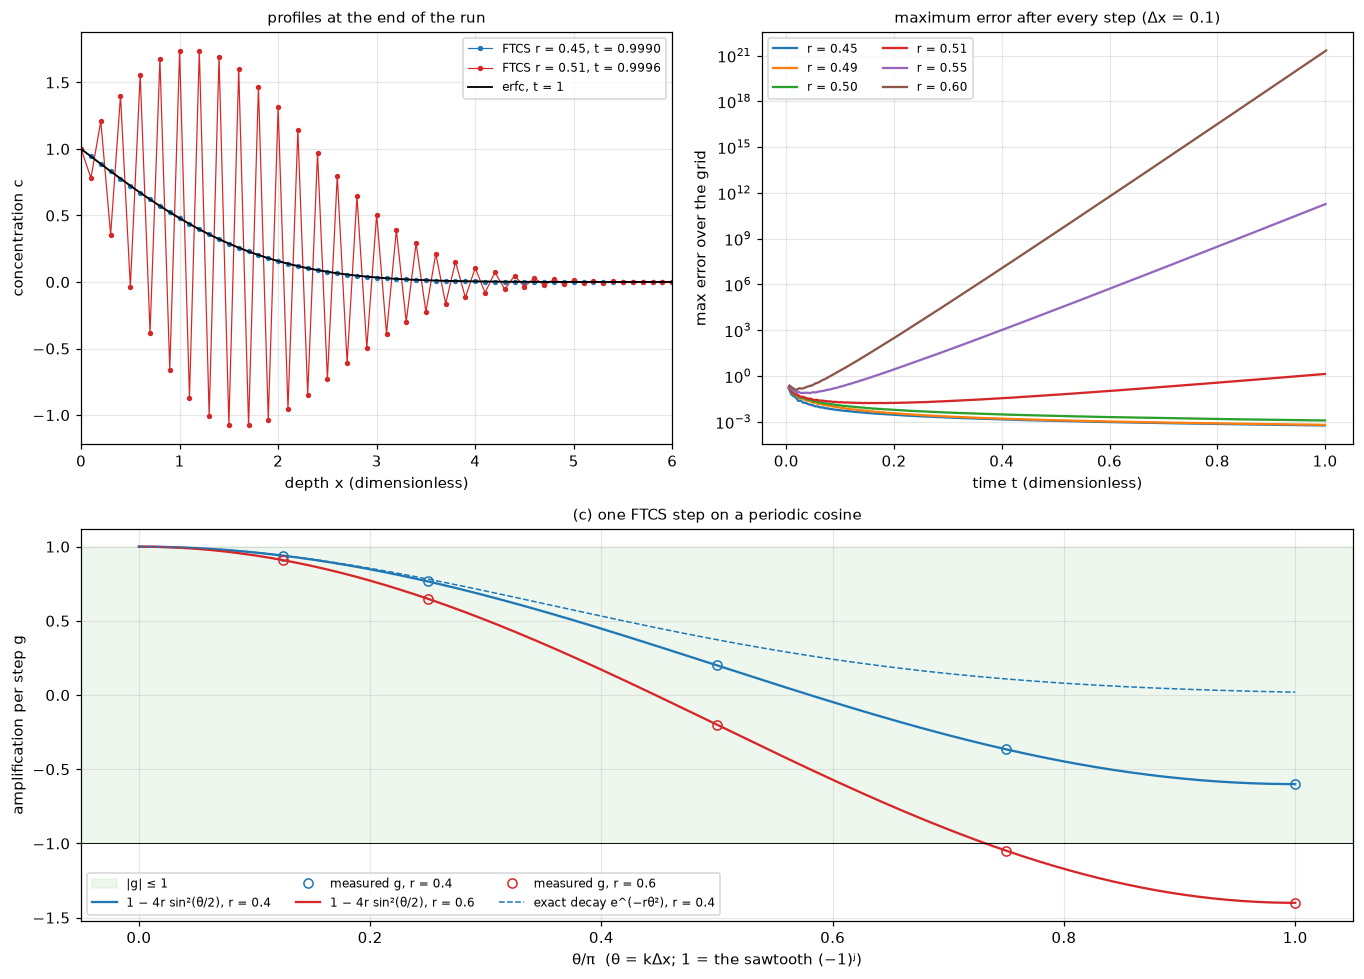

In [16]:
fig = plt.figure(figsize=(12.5, 9))
gsp = fig.add_gridspec(2, 2, height_ratios=[1, 0.95])
ax1, ax2, ax3 = fig.add_subplot(gsp[0, 0]), fig.add_subplot(gsp[0, 1]), fig.add_subplot(gsp[1, :])
for r_, col in ((0.45, 'C0'), (0.51, 'C3')):
    s = sweep[r_]
    ax1.plot(xg, s['c'], 'o-', ms=2.5, lw=0.8, color=col, label=f'FTCS r = {r_}, t = {s["N"] * s["dt"]:.4f}')
ax1.plot(xf, erfc_solution(xf, 1.0), 'k', lw=1.2, label='erfc, t = 1')
ax1.set_xlim(0, 6)
ax1.set_xlabel('depth x (dimensionless)')
ax1.set_ylabel('concentration c')
ax1.set_title('profiles at the end of the run', fontsize=10)
ax1.legend(fontsize=8)
for k, (r_, s) in enumerate(sweep.items()):
    ax2.semilogy(np.arange(1, s['N'] + 1) * s['dt'], s['errs'], color=f'C{k}', label=f'r = {r_:.2f}')
ax2.set_xlabel('time t (dimensionless)')
ax2.set_ylabel('max error over the grid')
ax2.set_title('maximum error after every step (Δx = 0.1)', fontsize=10)
ax2.legend(fontsize=8, ncol=2)
th = np.linspace(0, np.pi, 400)
ax3.axhspan(-1, 1, color='C2', alpha=0.08, label='|g| ≤ 1')
for r_, col in ((0.4, 'C0'), (0.6, 'C3')):
    ax3.plot(th / np.pi, amplification(r_, th), color=col, label=f'1 − 4r sin²(θ/2), r = {r_}')
    ax3.plot(TH / np.pi, g_meas[r_], 'o', ms=6, mfc='none', color=col, label=f'measured g, r = {r_}')
ax3.plot(th / np.pi, exact_decay(0.4, th), '--', color='C0', lw=1, label='exact decay e^(−rθ²), r = 0.4')
ax3.axhline(-1, color='k', lw=0.6)
ax3.set_xlabel('θ/π  (θ = kΔx; 1 = the sawtooth (−1)ʲ)')
ax3.set_ylabel('amplification per step g')
ax3.set_title('(c) one FTCS step on a periodic cosine', fontsize=10)
ax3.legend(fontsize=8, ncol=3, loc='lower left')
fig.tight_layout()
fig.savefig(FIG / 'fig2_stability.png', bbox_inches='tight')
plt.show()

**Reading the results:**

- **(a) The cliff at ½.** For r ≤ 0.50 the error at the end is below 1.3×10⁻³ and c stays in [0, 1]. At r = 0.51 the error first exceeds 1 at step 187 and ends at 1.37 with c between −1.08 and 1.74; r = 0.55 ends at 1.9×10¹¹ and r = 0.60 at 2.1×10²¹, after crossing 1 at step 14. The values above r = ½ are orders of magnitude only: they amplify round-off-level differences.
- **Why r = 0.51 first looks stable.** At the start the error is set by the starting error, the same as for the stable runs. The sawtooth part of the step-shaped initial data starts at about 10⁻³ and is multiplied by 1.04 per step; it takes over after a hundred-odd steps, and from then on log(error) is a straight line whose slope is ln|g|/Δt.
- **(b) The 40-step estimate is low, and it is the other modes.** The estimates 1.034, 1.193 and 1.391 are 0.5–0.7% below the formula. Repeating the estimate after longer runs moves them onto the formula: 1.03950 at step 6000 for r = 0.51 (the formula is 1.03950), 1.19936 against 1.19946 for r = 0.55, and 1.39906 against 1.39941 for r = 0.60. The modes next to p = M − 1 have |g| only slightly smaller, so it takes thousands of steps before the most dangerous one dominates alone; this confirms the explanation in 05.
- **(c)** One step multiplies a periodic cosine by exactly 1 − 4r sin²(θ/2), to 1×10⁻¹⁵. For r = 0.4, g stays between −0.6 and 1; short waves get the wrong (even negative) factor, but they decay. For r = 0.6 the factor passes −1 at θ ≈ 0.73π, and the sawtooth gets −1.4 per step. The long waves follow e^{−rθ²}, which is what makes the solution accurate.
- **(d) Why M = 10 does not blow up at r = 0.51.** With both ends fixed the shortest mode is p = M − 1, not the sawtooth (−1)ʲ, and its sin²((M − 1)π/(2M)) is below 1: the limit is 0.5125 for M = 10, so r = 0.51 converges to the steady state (3×10⁻¹⁵) while r = 0.515 grows to 4×10¹⁰. For M = 100 the limit is 0.50012, and r = 0.51 reaches 5×10⁴⁶ in 3000 steps. The formula agrees with the eigenvalues of the matrix to round-off. This does not contradict von Neumann: the periodic analysis gives the M → ∞ limit, ½, and is slightly conservative for a finite grid with fixed ends.
- **(e) Why r = 0.50 has twice the error of r = 0.49.** At r = ½ the run is the r = ¼ run on the even points: the two maximum errors are the same 1.2343809×10⁻³, and the even points agree with the coarse grid to 1×10⁻¹⁶. So the error of r = 0.50 is that of a grid with Δx = 0.2. In addition, the sawtooth is hardly damped: with fixed ends |g| = 0.9995 for r = 0.50, which after 200 steps still leaves 0.91 of the starting sawtooth, against 0.9595 for r = 0.49, which after 204 steps leaves 2.2×10⁻⁴. The odd points carry their own error, 2.7×10⁻⁴.

## Task 3: order of convergence and where the error comes from (lecture notes §5.5, §5.8)

### (a) r = 0.4, corner Cₛ

In [17]:
def conv_run(r_, dxs, corner=None):
    rows = []
    for dx_ in dxs:
        t0 = time.perf_counter()
        e = max_err(round(10 / dx_), 10.0, r_, 1.0, corner=corner)
        rows.append((dx_, e, time.perf_counter() - t0))
    return rows


def show(rows, label):
    print(label)
    print('     dx        M      N      max error      ratio    slope log2   time (s)')
    for k, (dx_, e, tm) in enumerate(rows):
        r_s = '' if k == 0 else f'{rows[k - 1][1] / e:7.3f}   {np.log2(rows[k - 1][1] / e):7.3f}'
        print(f'{dx_:9.5f}   {round(10 / dx_):5d}  {round(1 / (R_NOW * dx_ ** 2)):6d}   {e:.4e}    {r_s:20}  {tm:7.3f}')


DX_A = (0.1, 0.05, 0.025, 0.0125, 0.00625)
R_NOW = 0.4
conv_a = conv_run(0.4, DX_A)
show(conv_a, 'r = 0.4, corner Cs:')
for k, ref in ((1, '1.997'), (4, '2.000')):
    record('3a', f'slope, dx = {DX_A[k - 1]} -> {DX_A[k]}', np.log2(conv_a[k - 1][1] / conv_a[k][1]), 2, 'theory O(dx^2)', ref)
record('3a', 'max error, dx = 0.00625', conv_a[-1][1], None, '', '2.0009e-6')

r = 0.4, corner Cs:
     dx        M      N      max error      ratio    slope log2   time (s)
  0.10000     100     250   5.1123e-04                            0.001
  0.05000     200    1000   1.2804e-04      3.993     1.997       0.004
  0.02500     400    4000   3.2013e-05      4.000     2.000       0.018
  0.01250     800   16000   8.0034e-06      4.000     2.000       0.086
  0.00625    1600   64000   2.0009e-06      4.000     2.000       0.378


### (b) Predict first: r = 1/6

**Prediction, written before running:** lecture notes §5.5 say the leading truncation error vanishes at r = 1/6, which alone would give slope 4. But with the corner c₀⁰ = Cₛ the solution starts half a step early (Task 1), an error (Δt/2)c_t ∝ Δt = rΔx²/D, which is second order and much larger than the fourth-order truncation error. So the expected slope is 2, with the error close to (Δt/2)·0.2420 at T = 1.

In [18]:
DX_B = (0.2, 0.1, 0.05, 0.025, 0.0125)
R_NOW = 1 / 6
conv_b = conv_run(1 / 6, DX_B)
show(conv_b, 'r = 1/6, corner Cs:')
print('half-step prediction (dt/2) 0.2420 for each dx: ' + ', '.join(f'{(dx_ ** 2 / 6) / 2 * CT1:.4e}' for dx_ in DX_B))
record('3b', 'slope r=1/6 Cs, dx 0.025 -> 0.0125', np.log2(conv_b[3][1] / conv_b[4][1]), 2, 'half-step theory', '2.000')
record('3b', 'max error r=1/6 Cs, dx = 0.1', conv_b[1][1], 0.01 / 6 / 2 * CT1, 'half step (dt/2)*0.2420', '2.0159e-4')

r = 1/6, corner Cs:
     dx        M      N      max error      ratio    slope log2   time (s)
  0.20000      50     150   8.0593e-04                            0.001
  0.10000     100     600   2.0159e-04      3.998     1.999       0.002
  0.05000     200    2400   5.0403e-05      3.999     2.000       0.010
  0.02500     400    9600   1.2602e-05      4.000     2.000       0.041
  0.01250     800   38400   3.1506e-06      4.000     2.000       0.196
half-step prediction (dt/2) 0.2420 for each dx: 8.0657e-04, 2.0164e-04, 5.0411e-05, 1.2603e-05, 3.1507e-06


### (c) Finding the cause

The same r = 1/6 grids with the mean corner (Cₛ + C₀)/2 = 0.5; then, back to the corner Cₛ, compared with the exact solution at T + Δt/2.

In [19]:
conv_c = conv_run(1 / 6, DX_B, corner=0.5)
show(conv_c, 'r = 1/6, corner (Cs + C0)/2:')
record('3c', 'slope r=1/6 mean, dx 0.025 -> 0.0125', np.log2(conv_c[3][1] / conv_c[4][1]), 4, 'theory O(dx^4)', '4.000')
record('3c', 'max error r=1/6 mean, dx = 0.0125', conv_c[4][1], None, '', '1.7140e-11')
print()
print('dx = 0.1:   r       dt        corner Cs    (dt/2)*0.2420   Cs vs T + dt/2   mean corner')
for r_, ref in ((1 / 6, '6e-8'), (0.25, '6.78e-5'), (0.4, '1.899e-4')):
    dt_ = r_ * 0.01
    e_cs = max_err(100, 10.0, r_, 1.0)
    e_half = max_err(100, 10.0, r_, 1.0, t_exact=1.0 + dt_ / 2)
    e_mn = max_err(100, 10.0, r_, 1.0, corner=0.5)
    print(f'         {r_:6.4f}   {dt_:.3e}   {e_cs:.4e}   {dt_ / 2 * CT1:.4e}      {e_half:.4e}       {e_mn:.4e}')
    record('3c', f'r = {r_:.4g}: Cs vs exact at T + dt/2', e_half, e_mn, 'mean-corner run', ref)

r = 1/6, corner (Cs + C0)/2:
     dx        M      N      max error      ratio    slope log2   time (s)
  0.20000      50     150   1.1234e-06                            0.001
  0.10000     100     600   7.0187e-08     16.006     4.000       0.002
  0.05000     200    2400   4.3863e-09     16.001     4.000       0.009
  0.02500     400    9600   2.7419e-10     15.997     4.000       0.040
  0.01250     800   38400   1.7140e-11     15.997     4.000       0.220

dx = 0.1:   r       dt        corner Cs    (dt/2)*0.2420   Cs vs T + dt/2   mean corner
         0.1667   1.667e-03   2.0159e-04   2.0164e-04      6.1048e-08       7.0187e-08
         0.2500   2.500e-03   3.0889e-04   3.0246e-04      6.7789e-05       6.7848e-05
         0.4000   4.000e-03   5.1123e-04   4.8394e-04      1.8985e-04       1.9017e-04


### (d) Changing only Δt

Δx = 0.1 fixed, N = 200 … 4000 (r = 100/N), both corners. Δt → 0 is the method of lines of lecture notes §5.4: the semi-discrete system dc/dt = (D/Δx²)(Ac + b), here solved exactly in time by an eigen-decomposition of A (`method_of_lines`). Its error is the spatial error alone, the floor that both corners must reach as r → 0. The truncation error of the mean-corner run is (DΔx²/2)(r − 1/6)c_xxxx, the spatial part being the r-independent −(DΔx²/12)c_xxxx, so its global error should be the floor times |1 − 6r|.

In [20]:
xm, cm = method_of_lines(100, 10.0, 1.0)
e_mol = np.abs(cm - erfc_solution(xm, 1.0)).max()
print(f'r -> 0 limit (method of lines, exact in time): max error {e_mol:.4e} at x = {xm[np.argmax(np.abs(cm - erfc_solution(xm, 1.0)))]:.1f}')
print()
print('     N      r       corner Cs     mean corner   floor*|1 - 6r|   rel. diff (mean vs prediction)')
d_rows = {}
for N_ in (200, 250, 300, 400, 500, 600, 700, 800, 1000, 1250, 1600, 2000, 4000, 16000, 64000):
    r_ = 100 / N_
    e_cs, e_mn = max_err(100, 10.0, r_, 1.0), max_err(100, 10.0, r_, 1.0, corner=0.5)
    pred = e_mol * abs(1 - 6 * r_)
    d_rows[N_] = (r_, e_cs, e_mn, pred)
    rd = '' if N_ == 600 else f'{e_mn / pred - 1:+.2%}'
    print(f'{N_:6d}   {r_:7.5f}   {e_cs:.4e}    {e_mn:.4e}    {pred:.4e}       {rd}')
record('3d', 'mean corner, r = 1/6 (valley)', d_rows[600][2], None, '', '7.019e-8')
record('3d', 'mean corner, r = 0.4', d_rows[250][2], d_rows[250][3], 'r->0 limit x |1 - 6r|', '1.902e-4')
record('3d', 'mean corner, r = 0.025', d_rows[4000][2], d_rows[4000][3], 'r->0 limit x |1 - 6r|', '1.153e-4')
record('3d', 'corner Cs, r = 0.025', d_rows[4000][1], None, '', '1.310e-4')
record('3d', 'r -> 0 limit (method of lines)', e_mol, d_rows[64000][1], 'FTCS N = 64000, corner Cs', '~1.3e-4 (Cs)')

r -> 0 limit (method of lines, exact in time): max error 1.3567e-04 at x = 2.7

     N      r       corner Cs     mean corner   floor*|1 - 6r|   rel. diff (mean vs prediction)
   200   0.50000   1.2344e-03    2.7206e-04    2.7133e-04       +0.27%
   250   0.40000   5.1123e-04    1.9017e-04    1.8993e-04       +0.13%
   300   0.33333   4.2105e-04    1.3579e-04    1.3567e-04       +0.09%
   400   0.25000   3.0889e-04    6.7848e-05    6.7834e-05       +0.02%
   500   0.20000   2.4340e-04    2.7108e-05    2.7133e-05       -0.09%
   600   0.16667   2.0159e-04    7.0187e-08    0.0000e+00       
   700   0.14286   1.7400e-04    1.9429e-05    1.9381e-05       +0.24%
   800   0.12500   1.5634e-04    3.3967e-05    3.3917e-05       +0.15%
  1000   0.10000   1.3842e-04    5.4316e-05    5.4267e-05       +0.09%
  1250   0.08000   1.3103e-04    7.0592e-05    7.0547e-05       +0.06%
  1600   0.06250   1.2872e-04    8.4831e-05    8.4792e-05       +0.05%
  2000   0.05000   1.2863e-04    9.5001e-05    9.

 16000   0.00625   1.3443e-04    1.3059e-04    1.3058e-04       +0.00%


 64000   0.00156   1.3536e-04    1.3440e-04    1.3440e-04       +0.00%


### (e) Truncating the domain

r = 1/6, Δx = 0.05, mean corner, L = 2 … 8, right end Dirichlet and zero flux.

In [21]:
e_rows = {}
print('  L   right end    max error (whole domain)   at x    max error on 0 <= x <= 1   erfc(L/2)')
for L_ in (2, 3, 4, 5, 6, 8):
    for right in ('dirichlet', 'zero-flux'):
        x_, c_, _ = ftcs(round(L_ / 0.05), float(L_), 1 / 6, 1.0, right=right, corner=0.5)
        e_ = np.abs(c_ - erfc_solution(x_, 1.0))
        near = e_[x_ <= 1 + 1e-12].max()
        e_rows[(L_, right)] = (e_.max(), x_[np.argmax(e_)], near)
        print(f'{L_:3d}   {right:10}   {e_.max():.4e}                 {x_[np.argmax(e_)]:4.1f}    {near:.3e}                  {erfc(L_ / 2):.4e}')
record('3e', 'L = 4: max error (at x = L)', e_rows[(4, 'dirichlet')][0], erfc(2.0), 'erfc(L/2)', '4.678e-3')
record('3e', 'L = 8: max error (at x = L)', e_rows[(8, 'dirichlet')][0], erfc(4.0), 'erfc(L/2)', '1.542e-8')
record('3e', 'L = 5: max error on 0 <= x <= 1', e_rows[(5, 'dirichlet')][2], e_rows[(8, 'dirichlet')][2], 'L = 8 (no truncation)', '4.48e-9')
record('3e', 'L = 4, zero flux: max error 0<=x<=1', e_rows[(4, 'zero-flux')][2], None, '', '7.39e-7')

  L   right end    max error (whole domain)   at x    max error on 0 <= x <= 1   erfc(L/2)
  2   dirichlet    1.5730e-01                  2.0    3.349e-02                  1.5730e-01
  2   zero-flux    1.5726e-01                  2.0    3.349e-02                  1.5730e-01
  3   dirichlet    3.3895e-02                  3.0    4.062e-04                  3.3895e-02
  3   zero-flux    3.3895e-02                  3.0    4.062e-04                  3.3895e-02
  4   dirichlet    4.6777e-03                  4.0    7.470e-07                  4.6777e-03
  4   zero-flux    4.6777e-03                  4.0    7.388e-07                  4.6777e-03
  5   dirichlet    4.0695e-04                  5.0    4.476e-09                  4.0695e-04
  5   zero-flux    4.0695e-04                  5.0    4.309e-09                  4.0695e-04
  6   dirichlet    2.2090e-05                  6.0    4.386e-09                  2.2090e-05
  6   zero-flux    2.2090e-05                  6.0    4.386e-09                  

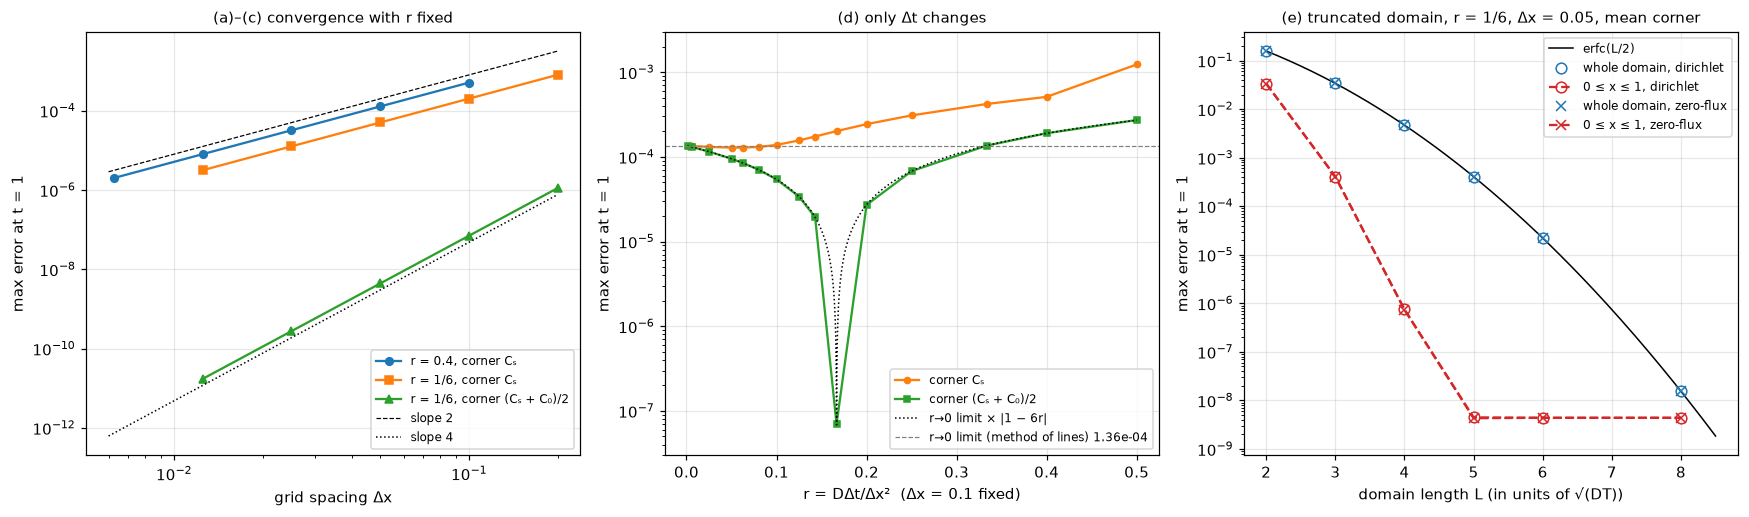

In [22]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))
for rows, lab, col, mk in ((conv_a, 'r = 0.4, corner Cₛ', 'C0', 'o'), (conv_b, 'r = 1/6, corner Cₛ', 'C1', 's'),
                           (conv_c, 'r = 1/6, corner (Cₛ + C₀)/2', 'C2', '^')):
    ax1.loglog([r_[0] for r_ in rows], [r_[1] for r_ in rows], mk + '-', color=col, ms=5, label=lab)
hh = np.array([0.006, 0.2])
ax1.loglog(hh, 2.0e-4 * (hh / 0.05) ** 2, 'k--', lw=0.8, label='slope 2')
ax1.loglog(hh, 3.0e-9 * (hh / 0.05) ** 4, 'k:', lw=1, label='slope 4')
ax1.set_xlabel('grid spacing Δx')
ax1.set_ylabel('max error at t = 1')
ax1.set_title('(a)–(c) convergence with r fixed', fontsize=10)
ax1.legend(fontsize=8)
rr = np.array([d_rows[n][0] for n in d_rows])
ax2.semilogy(rr, [d_rows[n][1] for n in d_rows], 'o-', ms=4, color='C1', label='corner Cₛ')
ax2.semilogy(rr, [d_rows[n][2] for n in d_rows], 's-', ms=4, color='C2', label='corner (Cₛ + C₀)/2')
rf = np.linspace(0.001, 0.5, 2000)
ax2.semilogy(rf, e_mol * np.abs(1 - 6 * rf), 'k:', lw=1, label='r→0 limit × |1 − 6r|')
ax2.axhline(e_mol, color='0.5', lw=0.8, ls='--', label=f'r→0 limit (method of lines) {e_mol:.2e}')
ax2.set_xlabel('r = DΔt/Δx²  (Δx = 0.1 fixed)')
ax2.set_ylabel('max error at t = 1')
ax2.set_title('(d) only Δt changes', fontsize=10)
ax2.set_ylim(3e-8, 3e-3)
ax2.legend(fontsize=8)
Ls = np.array([2, 3, 4, 5, 6, 8])
Lf = np.linspace(2, 8.5, 200)
ax3.semilogy(Lf, erfc(Lf / 2), 'k', lw=1, label='erfc(L/2)')
for right, mk in (('dirichlet', 'o'), ('zero-flux', 'x')):
    ax3.semilogy(Ls, [e_rows[(L_, right)][0] for L_ in Ls], mk, ms=7, mfc='none', color='C0', label=f'whole domain, {right}')
    ax3.semilogy(Ls, [e_rows[(L_, right)][2] for L_ in Ls], mk + '--', ms=7, mfc='none', color='C3', label=f'0 ≤ x ≤ 1, {right}')
ax3.set_xlabel('domain length L (in units of √(DT))')
ax3.set_ylabel('max error at t = 1')
ax3.set_title('(e) truncated domain, r = 1/6, Δx = 0.05, mean corner', fontsize=10)
ax3.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'fig3_convergence.png', bbox_inches='tight')
plt.show()

**Reading the results:**

- **(a) Second order.** 5.11×10⁻⁴, 1.28×10⁻⁴, 3.20×10⁻⁵, 8.00×10⁻⁶, 2.00×10⁻⁶ for Δx = 0.1 … 0.00625: slopes 1.997, 2.000, 2.000, 2.000. The finest grid takes 64,000 steps on 1601 points, 4096 times the work of the coarsest (16 times the points, 256 times the steps; lecture notes §5.10).
- **(b) Not fourth order.** At r = 1/6 with the corner Cₛ the slope is 2.000, as predicted, and the error at Δx = 0.1, 2.0159×10⁻⁴, is the half-step prediction (Δt/2)·0.2420 = 2.0164×10⁻⁴ to 0.03%. The half-step error is (Δt/2)c_t with Δt = rΔx²/D, so it is ∝ Δx², and it is far larger than the fourth-order truncation error that remains at r = 1/6.
- **(c) The cause is the start, not the update.** With the mean corner the same grids give 1.12×10⁻⁶ … 1.71×10⁻¹¹, slope 4.000. Keeping the corner Cₛ but comparing with the exact solution at T + Δt/2 gives the same small numbers as the mean corner (6.1×10⁻⁸ against 7.0×10⁻⁸ for r = 1/6; 6.779×10⁻⁵ against 6.785×10⁻⁵ for r = 0.25; 1.899×10⁻⁴ against 1.902×10⁻⁴ for r = 0.4). The measured order tests the whole program, starting values included, not just the update formula.
- **(d) Why the error does not go to 0 as Δt → 0, and why the valley is at 1/6.** As r → 0 FTCS becomes the method of lines, whose error is the spatial error alone; solved exactly, it is 1.357×10⁻⁴ here, and both corners approach it (1.354×10⁻⁴ and 1.344×10⁻⁴ at N = 64000). The mean-corner error is that floor times |1 − 6r| to within 0.3% for every r in the table (1.899×10⁻⁴ predicted against 1.902×10⁻⁴ at r = 0.4, 1.153×10⁻⁴ against 1.153×10⁻⁴ at r = 0.025): the time error +(DΔt/2)c_tt cancels the spatial error −(DΔx²/12)c_xxxx exactly at r = 1/6, which leaves the valley 7.0×10⁻⁸. The corner Cₛ adds the half-step error ∝ r, which fills in the valley.
- **(e) Truncation.** The largest error over the whole domain is always at x = L and equals erfc(L/2) (0.157, 0.0339, 4.68×10⁻³, 4.07×10⁻⁴, 2.21×10⁻⁵, 1.54×10⁻⁸), because c(L, T) is replaced by 0. Near the surface the effect is far smaller (3.3×10⁻², 4.1×10⁻⁴, 7.5×10⁻⁷, then 4.5×10⁻⁹ and 4.4×10⁻⁹ for L ≥ 5, the discretization error of this grid): the wrong boundary value has to diffuse back over the distance L before it is felt at the surface. Zero flux gives almost the same numbers. With L = 10, erfc(5) = 1.5×10⁻¹² is below every discretization error in this assignment, so the truncation never disturbs a convergence test.

## Task 4: gas carburizing of steel (lecture notes §5.9)

C₀ = 0.20 wt%, effective case depth = depth of 0.40 wt% C, D = 0.12 exp(−32 000/(1.987 T)) cm²/s (Wells and Mehl), converted to m²/s.

### (a)–(b) Diffusivity and the erfc schedule (Cₛ = 1.00 wt%)

In [23]:
print(' T (C)    D (m^2/s)       t(0.5 mm)   t(1.0 mm)   t(1.5 mm)    (hours)')
sched = {}
for T_, ref_d, refs in ((875, '9.716e-12', ('2.70', '10.80', '24.31')), (900, '1.310e-11', ('2.00', '8.01', '18.03')),
                        (925, '1.745e-11', ('1.50', '6.02', '13.54')), (950, '2.296e-11', ('1.14', '4.57', '10.28')),
                        (975, '2.989e-11', ('0.88', '3.51', '7.90'))):
    D_ = wells_mehl(T_)
    hrs = [case_time(d, D_, 1.0) / HOUR for d in (0.5e-3, 1.0e-3, 1.5e-3)]
    sched[T_] = (D_, hrs, ref_d, refs)
    print(f' {T_}    {D_:.4e}      {hrs[0]:6.3f}      {hrs[1]:6.3f}      {hrs[2]:6.3f}')
for T_ in (875, 925, 975):
    record('4a', f'D({T_} C) (m^2/s)', sched[T_][0], None, '', sched[T_][2])
for d, h, ref in zip((0.5, 1.0, 1.5), sched[925][1], sched[925][3]):
    record('4b', f't({d} mm), 925 C (h)', h, None, '', ref)
for T_ in (875, 975):
    record('4b', f't(1.0 mm), {T_} C (h)', sched[T_][1][1], None, '', sched[T_][3][1])
D = sched[925][0]
print(f'\n1.0 -> 1.5 mm at 925 C: x {sched[925][1][2] / sched[925][1][1]:.4f};   925 -> 975 C: D x {sched[975][0] / D:.4f}, time / {sched[925][1][1] / sched[975][1][1]:.4f}')
print(f'875 -> 975 C: D x {sched[975][0] / sched[875][0]:.3f}')

 T (C)    D (m^2/s)       t(0.5 mm)   t(1.0 mm)   t(1.5 mm)    (hours)
 875    9.7161e-12       2.701      10.802      24.305
 900    1.3101e-11       2.003       8.011      18.025
 925    1.7446e-11       1.504       6.016      13.536
 950    2.2962e-11       1.143       4.571      10.284
 975    2.9892e-11       0.878       3.511       7.900

1.0 -> 1.5 mm at 925 C: x 2.2500;   925 -> 975 C: D x 1.7133, time / 1.7133
875 -> 975 C: D x 3.077


### (c) FTCS, single stage

925 °C, Cₛ = 1.00, L = 6 mm, Δx = 10 μm, run to the 1.0 mm time of (b) with N = ceil(t/Δt₀), Δt = t/N (r slightly below 0.4).

In [24]:
t1 = case_time(1e-3, D, 1.0)
s_runs = {}
for corner, ref_e, ref_d in (('cs', '1.08e-5', '1.00002'), ('mean', '4.0e-6', '1.00000')):
    s = single_stage(D, 1.0, t1, corner=corner)
    e = np.abs(s['c'] - erfc_solution(s['x'], t1, D, 1.0, C0))
    dep = depth_interp(s['x'], s['c'], CASE)
    s_runs[corner] = s
    print(f'corner {corner:4}: t = {t1:.1f} s = {t1 / HOUR:.4f} h, dt = {s["dt"]:.4f} s, N = {s["N"]}, r = {s["r"]:.5f}')
    print(f'             max error {e.max():.3e} wt% at x = {s["x"][np.argmax(e)] * 1e3:.2f} mm;  depth of 0.40 wt% = {dep * 1e3:.6f} mm ({(dep - 1e-3) * 1e6:+.4f} um)')
    record('4c', f'max error, corner {corner} (wt%)', e.max(), None, '', ref_e)
    record('4c', f'case depth, corner {corner} (mm)', dep * 1e3, 1.0, 'erfc design depth', ref_d)
record('4c', 'N', s_runs['cs']['N'], None, '', '9447')
record('4c', 'dt (s)', s_runs['cs']['dt'], None, '', '2.2925')
print(f'L = 6 mm is {6e-3 / np.sqrt(D * t1):.1f} sqrt(Dt); truncation error erfc(L/(2 sqrt(Dt))) = {erfc(6e-3 / (2 * np.sqrt(D * t1))):.1e}')

corner cs  : t = 21657.4 s = 6.0160 h, dt = 2.2925 s, N = 9447, r = 0.39996
             max error 1.084e-05 wt% at x = 0.70 mm;  depth of 0.40 wt% = 1.000024 mm (+0.0241 um)
corner mean: t = 21657.4 s = 6.0160 h, dt = 2.2925 s, N = 9447, r = 0.39996
             max error 4.024e-06 wt% at x = 1.68 mm;  depth of 0.40 wt% = 0.999998 mm (-0.0025 um)
L = 6 mm is 9.8 sqrt(Dt); truncation error erfc(L/(2 sqrt(Dt))) = 5.1e-12


### (d) FTCS, two stages: boost 3 h at C_b = 1.10 wt%, then diffuse at C_d = 0.80 wt%

Δt divides 3 h exactly; the corner is (C_b + C₀)/2 and the surface value at the switching step is (C_b + C_d)/2. The run stops at the first step where the depth of 0.40 wt% is ≥ 1.0 mm. The exact time is found with `brentq` from the superposition c = C₀ + (C_b − C₀) erfc(x/(2√(Dt))) + (C_d − C_b) erfc(x/(2√(D(t − t_b))))).

In [25]:
tb = 3 * HOUR
t0 = time.perf_counter()
ts = two_stage(D, 1.10, 0.80, tb)
t_ex = two_stage_exact_time(D, 1.10, 0.80, tb)
ex_prof = two_stage_solution(ts['x'], ts['t'], tb, D, 1.10, 0.80, C0)
err2 = np.abs(ts['c'] - ex_prof).max()
d_boost = depth_interp(ts['x'], ts['boost'], CASE)
d_boost_ex = depth_exact((CASE - C0) / (1.10 - C0), tb, D)
t080, t110 = case_time(1e-3, D, 0.80), case_time(1e-3, D, 1.10)
print(f'dt = {ts["dt"]:.6f} s, 3 h = {ts["Nb"]} steps exactly ({ts["Nb"] * ts["dt"] / HOUR:.12f} h), r = {ts["r"]:.5f}')
print(f'case depth at the end of the boost: {d_boost * 1e3:.4f} mm (erfc at C_b: {d_boost_ex * 1e3:.4f} mm)')
print(f'1.0 mm first reached at step {ts["n"]}: total {ts["t"] / HOUR:.4f} h, diffusion stage {(ts["t"] - tb) / HOUR:.4f} h')
print(f'superposition + brentq: total {t_ex / HOUR:.5f} h, diffusion stage {(t_ex - tb) / HOUR:.5f} h; FTCS - exact = {ts["t"] - t_ex:.2f} s (one step = {ts["dt"]:.2f} s)')
print(f'max |FTCS - superposition| at the end = {err2:.2e} wt%')
print(f'single stage to 1.0 mm: Cs = 0.80: {t080 / HOUR:.3f} h;  Cs = 1.10: {t110 / HOUR:.3f} h;  boost-diffuse saves {(t080 - t_ex) / HOUR:.2f} h ({1 - t_ex / t080:.0%})')
print(f'(run time {time.perf_counter() - t0:.1f} s)')
record('4d', 'total time (h)', ts['t'] / HOUR, t_ex / HOUR, 'superposition + brentq', '6.373')
record('4d', 'diffusion stage (h)', (ts['t'] - tb) / HOUR, (t_ex - tb) / HOUR, 'superposition + brentq', '3.373')
record('4d', 'max error vs superposition (wt%)', err2, None, '', '3.1e-6')
record('4d', 'case depth at end of boost (mm)', d_boost * 1e3, d_boost_ex * 1e3, 'erfc at C_b', '0.749')
record('4d', 'single stage 0.80: t(1 mm) (h)', t080 / HOUR, None, '', '8.51')
record('4d', 'single stage 1.10: t(1 mm) (h)', t110 / HOUR, None, '', '5.34')

dt = 2.292507 s, 3 h = 4711 steps exactly (3.000000000000 h), r = 0.39996
case depth at the end of the boost: 0.7493 mm (erfc at C_b: 0.7493 mm)
1.0 mm first reached at step 10008: total 6.3732 h, diffusion stage 3.3732 h
superposition + brentq: total 6.37296 h, diffusion stage 3.37296 h; FTCS - exact = 0.76 s (one step = 2.29 s)
max |FTCS - superposition| at the end = 3.09e-06 wt%
single stage to 1.0 mm: Cs = 0.80: 8.506 h;  Cs = 1.10: 5.343 h;  boost-diffuse saves 2.13 h (25%)
(run time 0.1 s)


### (e) Cost

In [26]:
print('  dx (um)   dt limit dx^2/(2D) (s)   steps of (c) at r = 0.4   (t/dt0 before ceil)   grid intervals L/dx (L = 5 mm)')
for dx_, ref_t, ref_n in ((10e-6, '2.87', '9,446'), (5e-6, '0.72', '37,784'), (1e-6, '0.029', '944,606')):
    lim = dx_ ** 2 / (2 * D)
    n_c = grid_steps(D, t1, dx_)[1]
    print(f'{dx_ * 1e6:7.0f}     {lim:10.4f}                {n_c:9,d}                 {t1 / (0.4 * dx_ ** 2 / D):12.2f}          {round(5e-3 / dx_):6d}')
    record('4e', f'dt limit, dx = {dx_ * 1e6:.0f} um (s)', lim, None, '', ref_t)
    record('4e', f'steps at r = 0.4, dx = {dx_ * 1e6:.0f} um', n_c, None, '', ref_n)

  dx (um)   dt limit dx^2/(2D) (s)   steps of (c) at r = 0.4   (t/dt0 before ceil)   grid intervals L/dx (L = 5 mm)
     10         2.8659                    9,447                      9446.06             500
      5         0.7165                   37,785                     37784.22            1000
      1         0.0287                  944,606                    944605.54            5000


### Model uncertainty (validation)

The numerical error is now known to be about 10⁻⁵ wt%. The model behind it has larger uncertainties. Two of them can be put in numbers with the data given in lecture notes §5.9 and the assignment: (1) another literature value of D, 1.5×10⁻¹¹ m²/s at 927 °C (Callister); (2) the concentration dependence quoted by the assignment, D ∝ 0.07 + 0.06 × %C, which the constant-D model ignores.

In [27]:
D927 = wells_mehl(927)
print(f'D(927 C): Wells-Mehl {D927:.3e} m^2/s, Callister 1.5e-11: ratio {D927 / 1.5e-11:.3f}')
print(f't(1.0 mm) with Cs = 1.00: Wells-Mehl at 925 C {t1 / HOUR:.2f} h, with D = 1.5e-11 {case_time(1e-3, 1.5e-11, 1.0) / HOUR:.2f} h')
print(f'D0 = 0.07 + 0.06 %C equals 0.12 cm^2/s at {(0.12 - 0.07) / 0.06:.2f} wt% C; D(1.0 %C)/D(0.2 %C) = {0.13 / 0.082:.3f}')
for C_ in (0.2, 0.4, 0.7, 1.0):
    print(f'   constant D taken at {C_:.1f} wt% C: t(1.0 mm) = {case_time(1e-3, D * (0.07 + 0.06 * C_) / 0.12, 1.0) / HOUR:.2f} h')
record('4', 'D(927 C), Wells-Mehl (m^2/s)', D927, 1.5e-11, 'Callister (927 C)', '')

D(927 C): Wells-Mehl 1.784e-11 m^2/s, Callister 1.5e-11: ratio 1.189
t(1.0 mm) with Cs = 1.00: Wells-Mehl at 925 C 6.02 h, with D = 1.5e-11 7.00 h
D0 = 0.07 + 0.06 %C equals 0.12 cm^2/s at 0.83 wt% C; D(1.0 %C)/D(0.2 %C) = 1.585
   constant D taken at 0.2 wt% C: t(1.0 mm) = 8.80 h
   constant D taken at 0.4 wt% C: t(1.0 mm) = 7.68 h
   constant D taken at 0.7 wt% C: t(1.0 mm) = 6.45 h
   constant D taken at 1.0 wt% C: t(1.0 mm) = 5.55 h


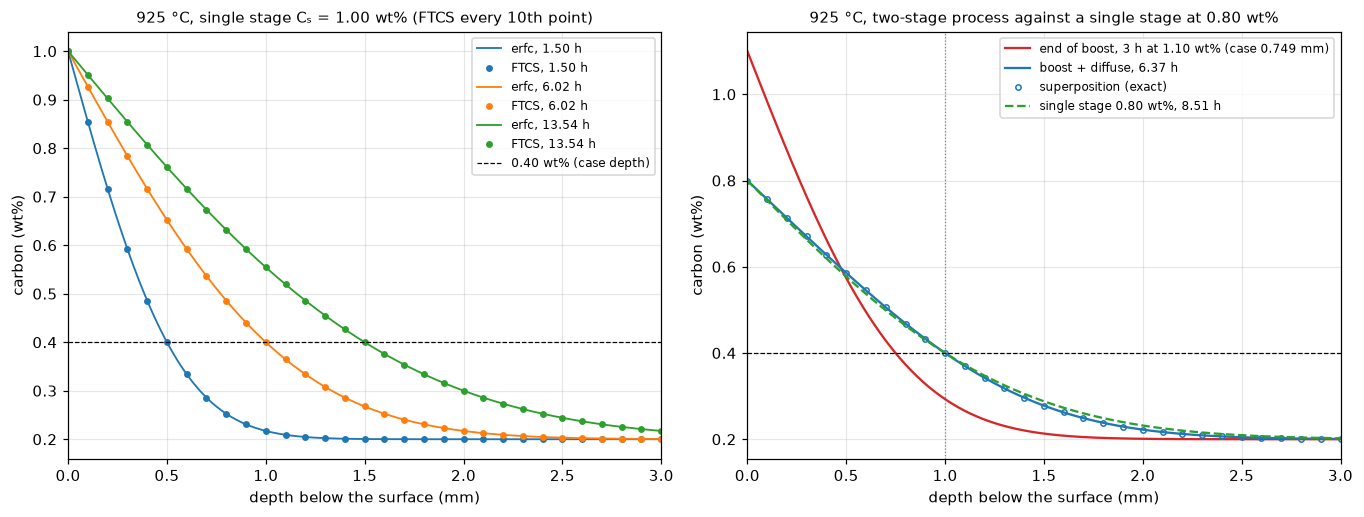

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for k, d in enumerate((0.5e-3, 1.0e-3, 1.5e-3)):
    tt = case_time(d, D, 1.0)
    s = single_stage(D, 1.0, tt, corner='mean')
    xmm = s['x'] * 1e3
    ax1.plot(xmm, erfc_solution(s['x'], tt, D, 1.0, C0), color=f'C{k}', lw=1.2, label=f'erfc, {tt / HOUR:.2f} h')
    ax1.plot(xmm[:301:10], s['c'][:301:10], 'o', ms=3.5, color=f'C{k}', label=f'FTCS, {tt / HOUR:.2f} h')
ax1.axhline(CASE, color='k', lw=0.8, ls='--', label='0.40 wt% (case depth)')
ax1.set_xlim(0, 3)
ax1.set_xlabel('depth below the surface (mm)')
ax1.set_ylabel('carbon (wt%)')
ax1.set_title('925 °C, single stage Cₛ = 1.00 wt% (FTCS every 10th point)', fontsize=10)
ax1.legend(fontsize=8)
s080 = single_stage(D, 0.80, t080, corner='mean')
xmm = ts['x'] * 1e3
boost_plot = ts['boost'].copy()
boost_plot[0] = 1.10        # the stored step holds the switching-step average (C_b + C_d)/2 at x = 0; show C_b
ax2.plot(xmm, boost_plot, color='C3', label=f'end of boost, 3 h at 1.10 wt% (case {d_boost * 1e3:.3f} mm)')
ax2.plot(xmm, ts['c'], color='C0', label=f'boost + diffuse, {ts["t"] / HOUR:.2f} h')
ax2.plot(xmm[:301:10], ex_prof[:301:10], 'o', ms=3.5, mfc='none', color='C0', label='superposition (exact)')
ax2.plot(s080['x'] * 1e3, s080['c'], '--', color='C2', label=f'single stage 0.80 wt%, {t080 / HOUR:.2f} h')
ax2.axhline(CASE, color='k', lw=0.8, ls='--')
ax2.axvline(1.0, color='0.5', lw=0.8, ls=':')
ax2.set_xlim(0, 3)
ax2.set_xlabel('depth below the surface (mm)')
ax2.set_ylabel('carbon (wt%)')
ax2.set_title('925 °C, two-stage process against a single stage at 0.80 wt%', fontsize=10)
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'fig4_carburizing.png', bbox_inches='tight')
plt.show()

**Reading the results:**

- **(a)–(b) Schedule.** D(925 °C) = 1.745×10⁻¹¹ m²/s; the 1.0 mm case takes 6.02 h at 925 °C, 10.80 h at 875 °C and 3.51 h at 975 °C. Going from 1.0 to 1.5 mm multiplies the time by exactly 1.5² = 2.25 (depth ∝ √t); going from 925 to 975 °C multiplies D by 1.713 and divides the time by the same factor.
- **(c) Real units.** The run takes N = 9447 steps of 2.2925 s (r = 0.39996). Against erfc the largest error is 1.08×10⁻⁵ wt% with the corner Cₛ and 4.0×10⁻⁶ wt% with the mean corner; the case depth comes out as 1.000024 mm and 0.999998 mm, both within 0.1 μm of the design depth. L = 6 mm is 9.8√(Dt), so the truncation of the domain contributes about 5×10⁻¹².
- **(d) Boost–diffuse.** Δt = 2.2925 s divides 3 h into 4711 steps exactly. The 1.0 mm case is reached at step 10008: 6.373 h in total, 3.373 h of diffusion, within one step (0.8 s) of the exact 6.37296 h from the superposition; the profile differs from the superposition by at most 3.1×10⁻⁶ wt%. At the end of the boost the case is already 0.749 mm. Single stages need 8.51 h at 0.80 wt% (a suitable surface carbon) and 5.34 h at 1.10 wt% (a surface that is too rich); boost–diffuse reaches the same case with a 0.80 wt% surface in 2.13 h (25%) less time. Superposition works because the equation is linear when D is constant: the change of the surface value at t_b is itself an erfc problem starting at t_b. If D depends on carbon, the equation becomes nonlinear and superposition fails; FTCS then needs the flux form with D at the half points, D_{i±½}, and a step limited by the largest D.
- **(e) Cost.** The stability limit Δx²/(2D) is 2.87 s at 10 μm and 0.029 s at 1 μm; a single-stage run needs 9447 and 944,606 steps, on 500 and 5000 intervals: 1000 times the work for a resolution that a millimetre-scale case does not need.
- **What limits the answer is the model, not the numerics.** An error of 10⁻⁵ wt% is far below what a carbon analysis can resolve. Callister's D at 927 °C, 1.5×10⁻¹¹ m²/s, is 16% below Wells–Mehl at the same temperature (1.784×10⁻¹¹); with it the 1.0 mm case takes 7.00 h instead of 6.02 h. The concentration dependence matters even more: with the prefactor 0.07 + 0.06 × %C evaluated at 0.2 or 1.0 wt% C, the constant-D time ranges from 8.80 h to 5.55 h; the constant 0.12 cm²/s corresponds to 0.83 wt% C in that expression. Finite surface reaction rates and alloying elements add further uncertainty. This is the difference between verification (the program solves the equations correctly, to 10⁻⁵ wt%) and validation (the equations describe the furnace, here uncertain by tens of per cent in time).

## Summary table

- `check`: an independent reference value. It is a theoretical value, a closed form or exact formula, the predicted truncation error, another run, the method-of-lines limit, the superposition solution, or a literature value; the `check from` column says which. `rel. diff` is the difference of this run relative to `check`.
  - Rows marked (mag.) are compared only in order of magnitude.
- `05`: the value printed in the course's reference solution, for reference only. Entries marked (mag.) are numbers that 05 itself calls "order of magnitude".

In [29]:
print(f'{"task":4}  {"quantity":38} {"this run":>14} {"check":>14}  {"check from":27} {"rel. diff":>9}   {"05":>17}')
print('-' * 136)
for task, name, ours, check, how, ref05 in summary:
    if check is None:
        chk, rd = '', ''
    else:
        chk = f'{check:14.8g}'
        rd = f'{abs(ours):8.1e}*' if check == 0 else f'{abs(ours - check) / abs(check):9.1e}'
    print(f'{task:4}  {name:38} {ours:14.8g} {chk:>14}  {how:27} {rd:>9}   {ref05:>17}')
print('* check value is 0: absolute value shown instead of relative difference')

task  quantity                                     this run          check  check from                  rel. diff                  05
----------------------------------------------------------------------------------------------------------------------------------------
0     erf(1)                                     0.84270079     0.84270079  Simpson N=1000 (week 1)       1.1e-14            0.842701
0     erfc(2)                                   0.004677735    0.004677735  1 - Simpson N=1000            1.6e-11           4.6777e-3
0     max |Simpson - erf|, six z              7.3607787e-14              0  exact                        7.4e-14*               7e-14
0     erfcinv(0.5)                               0.47693628     0.47693628  brentq on erfc                2.3e-16            0.476936
0     erfcinv(0.25)                              0.81341985     0.81341985  brentq on erfc                2.7e-16            0.813420
0     erfcinv(0.01)                               1.8213864

## Differences from the reference solution (05)

Most numbers in 05 agree with this run to the digits they give, including the order-of-magnitude rows of Task 2. The points below are where the two differ, or where this run adds a check that 05 does not have.

1. **Task 3(d): the limit r → 0.** The assignment says the mean-corner error approaches about 1.2×10⁻⁴ as r → 0, and 05's table ends at r = 0.025 with 1.153×10⁻⁴.
   - Solving the semi-discrete system exactly in time (the method of lines, the r → 0 limit of FTCS) gives the actual floor, 1.357×10⁻⁴ for this grid. Both corners approach it: 1.344×10⁻⁴ (mean) and 1.354×10⁻⁴ (Cₛ) at N = 64000.
   - The mean-corner error rises toward the floor as r decreases below 1/6: it is the floor times |1 − 6r| to within 0.3% for every r in the table. So 1.15×10⁻⁴ at r = 0.025 is a point on the way, not the limit.
2. **Task 4(e): steps at r = 0.4.** 05 lists 9,446 and 37,784 steps for Δx = 10 and 5 μm. With the rule of Task 4(c), N = ceil(t/Δt₀), the counts are 9447 (the N that 05 itself gives in (c)) and 37,785; 05's values are t/Δt₀ = 9446.06 and 37,784.2 rounded down. For 1 μm both rules give 944,606.
3. **Task 2(b): the 40-step estimate.** 05 explains the 0.5% shortfall of the estimates by the less dangerous modes still mixed in. This run confirms it: after longer runs the same 40-step estimate converges to the formula (1.03950 against 1.03950 for r = 0.51 at step 6000).
4. **Task 1: the negative errors for x > 3.** 05 attributes them to the truncation term. The decomposition of Task 1 makes this quantitative: the error equals the half-step part (Δt/2)c_t, positive everywhere, plus the mean-corner error, to 6×10⁻⁷; the negative values are where the second part, negative from x = 1.5 on, outweighs the first.
5. **Numbers that 05 calls "order of magnitude":** 1.37 for r = 0.51 (05: about 1.4), 1.9×10¹¹ (about 2×10¹¹), 2.1×10²¹ (about 2×10²¹), 4.3×10¹⁰ for M = 10, r = 0.515 (4×10¹⁰), 4.6×10⁴⁶ for M = 100, r = 0.51 (5×10⁴⁶). The steps at which r = 0.51 and 0.60 first exceed 1, 187 and 14, are the same.

Small inconsistencies in the lecture notes, for the record: §5.6 refers to "Task 2(d)" for the r = ½ comparison, which is Task 2(e) in the assignment, and §5.7 to "Task 2(c)" for M = 10, which is Task 2(d); and §5.9 attributes the Wells–Mehl prefactor 0.12 cm²/s to 0.7 wt% C, while 0.07 + 0.06 × %C equals 0.12 at 0.83 wt% C.